# Time series data modelling

In [64]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

<div class="alert alert-success">
    <b>EXERCISE: Data download and transformation</b>:
    <ul>
        <li>Download the Close prices for the following tickers: 
            <code>'JPM', 'BAC', 'C', 'GS', 'MS'</code> 
            using <code>yfinance</code>. Set the start date to <code>'2010-01-01'</code> and the end date to <code>'2025-08-31'</code>.</li>
        <li>Transform the Adjusted Close prices into log returns for each stock and times 100.
        <li>Create a new DataFrame named <code>log_returns</code> to store the calculated log returns for all stocks.</li>
        <li>Drop missing values (e.g., NaN values) resulting from the transformation.</li>
        <li>Visualize the Price and log returns of <code>'JPM'</code> using line plot.</li>
    </ul>
</div>

In [65]:
tickers = ['JPM', 'BAC', 'C', 'GS', 'MS']
data = yf.download(tickers, start="2010-01-01", end="2025-08-31")['Close']
log_returns = 100 * np.log(data / data.shift(1))
log_returns = log_returns.dropna()
log_returns

[*********************100%***********************]  5 of 5 completed


Ticker,BAC,C,GS,JPM,MS
Date,,,,,
2010-01-05,3.198782,3.752213,1.752571,1.918423,3.590559
2010-01-06,1.165963,3.068567,-1.073093,0.547943,1.271525
2010-01-07,3.241638,0.274373,1.937988,1.961556,1.437992
2010-01-08,-0.889948,-1.657516,-1.909295,-0.245911,-2.056255
2010-01-11,0.889948,1.108094,-1.590187,-0.336341,-0.653262
...,...,...,...,...,...
2025-08-25,0.000000,-0.273321,-0.418740,-0.453353,-0.250292
2025-08-26,1.544194,0.755047,1.365857,1.236798,0.890055
2025-08-27,0.258381,1.194260,0.096086,0.237523,0.274844


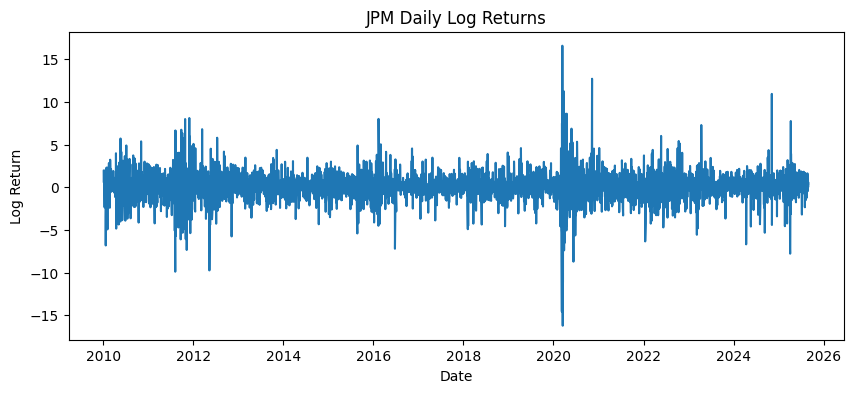

In [66]:
plt.figure(figsize=(10, 4))
plt.plot(log_returns['JPM'])
plt.title('JPM Daily Log Returns')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.show()

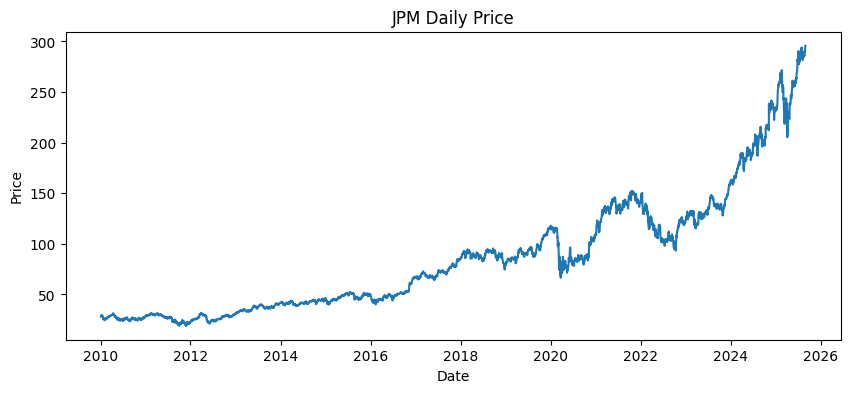

In [67]:
plt.figure(figsize=(10, 4))
plt.plot(data['JPM'])
plt.title('JPM Daily Price')
plt.xlabel('Date')
plt.ylabel('Price')
plt.show()

Why is stationary matter?

Check Stationarity (ADF Test)

In [68]:
from statsmodels.tsa.stattools import adfuller

jpm_price = data['JPM'].to_numpy()

adf_result = adfuller(jpm_price)
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4])

ADF Statistic: 2.5499241733682694
p-value: 0.9990642010097172
Critical Values: {'1%': np.float64(-3.4320171546099365), '5%': np.float64(-2.8622766576624628), '10%': np.float64(-2.5671621313805835)}


In [69]:
#We can see that the close price of JPM is not stationary, now test for log returns of JPM
jpm_return = log_returns['JPM'].to_numpy()

adf_result = adfuller(jpm_return)
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4])

#according the ADF test, log-returns are stationary (pvalue << 1%)

ADF Statistic: -12.730322854973252
p-value: 9.405983540919361e-24
Critical Values: {'1%': np.float64(-3.4320231263589913), '5%': np.float64(-2.862279295629063), '10%': np.float64(-2.567163535727597)}


## Autoregressive (AR) Model

$$
X_t = \phi_0 + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \dots + \phi_p X_{t-p} + \epsilon_t
$$

### PACF

When modeling real data with an AR model, the order $p$ is unknown. Determining $p$ is called the problem of order selection. Common methods include the partial autocorrelation function (PACF) and the AIC or BIC criterion.

Let $X_1, \ldots, X_n, Y$ be random variables, and define

$$
L(Y|X_1, \ldots, X_n) = \arg\min_{\hat{Y}=b_0+b_1X_1+\cdots+b_nX_n} E(Y-\hat{Y})^2,
$$

which is called the best linear prediction of $Y$ using $X_1, \ldots, X_n$. The correlation coefficient between $Y - L(Y|X_1, \ldots, X_n)$ and $Z - L(Z|X_1, \ldots, X_n)$ is called the **partial correlation coefficient** between $Y$ and $Z$ after removing the effect of $X_1, \ldots, X_n$.

For a stationary linear time series, for $n=1,2,\ldots$, we have

$$
L(X_t | X_{t-1}, \ldots, X_{t-n}) = \phi_{n0} + \phi_{n1} X_{t-1} + \cdots + \phi_{nn} X_{t-n},
$$

where $\phi_{nj}, j=0,1,\ldots,n$ are independent of $t$. $\phi_{nn}$ is the **partial autocorrelation coefficient** of the time series $\{X_t\}$, and the sequence $\{\phi_{nn}\}$ is called the **partial autocorrelation function (PACF)** of the time series $\{X_t\}$.

In fact, $\phi_{nn}$ is the partial correlation coefficient between $X_t$ and $X_{t-n}$ after removing the effect of $X_{t-1}, \ldots, X_{t-(n-1)}$. In particular, $\phi_{11} = \rho_1$.

The sample estimate of $\phi_{nn}$, denoted $\hat{\phi}_{nn}, n=1,2,\ldots$, is called the **sample partial autocorrelation function**. In Python, it can be estimated and plotted using plot_pacf() from statsmodels.

If ${X_t}$ follows the AR($p$) model:

$$
X_t = \phi_0 + \phi_1 X_{t-1} + \cdots + \phi_p X_{t-p} + \varepsilon_t, \quad \phi_p \neq 0,
$$

this means that when predicting $X_t$ using a linear combination of $X_{t-1}, \ldots, X_{t-p}$, only these lags are needed. Adding $X_{t-p-1}, X_{t-p-2}, \ldots$ does not improve the prediction. This implies that $\hat{\phi}_{kk}=0, k>p$. This property is called the cut-off property of the PACF for AR models.


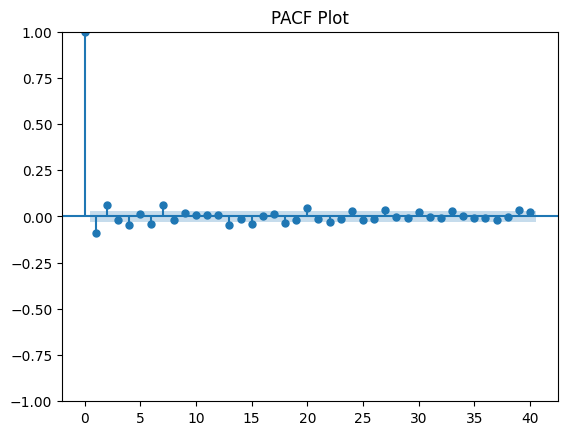

In [70]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(jpm_return, lags=40)
plt.title("PACF Plot")
plt.show()

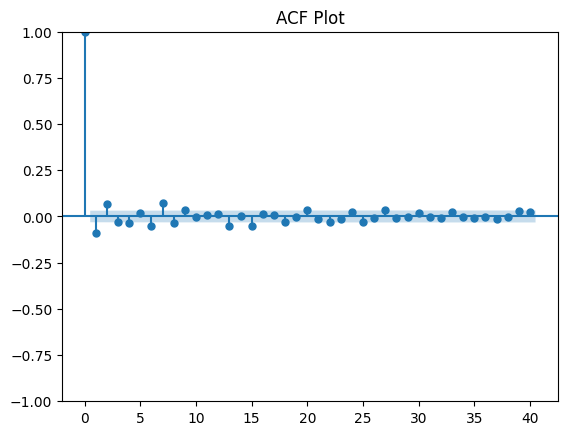

In [71]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(jpm_return, lags=40)
plt.title("ACF Plot")
plt.show()

There are generally 2 ways of fitting a AR model, ARIMA is prefered, standard errors are more precise.

In [72]:
from statsmodels.tsa.ar_model import AutoReg

ar_model = AutoReg(jpm_return, lags=1).fit()
ar_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            AutoReg Model Results                             
==============================================================================
Dep. Variable:                      y   No. Observations:                 3938
Model:                     AutoReg(1)   Log Likelihood               -7761.702
Method:               Conditional MLE   S.D. of innovations              1.738
Date:                Sat, 26 Sep 2026   AIC                          15529.404
Time:                        13:18:24   BIC                          15548.239
Sample:                             1   HQIC                         15536.086
                                 3938                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0646      0.028      2.330      0.020       0.010       0.119
y.L1          -0.0889      0.016     -5.602      0.000      -0.120      -0.058
                                    Roots                                    
=============================================================================
                  Real          Imaginary           Modulus         Frequency
-----------------------------------------------------------------------------
AR.1          -11.2472           +0.0000j           11.2472            0.5000
-----------------------------------------------------------------------------
"""

In [73]:
from statsmodels.tsa.arima.model import ARIMA

ar_model = ARIMA(jpm_return, order=(1, 0, 0)).fit()
ar_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 3938
Model:                 ARIMA(1, 0, 0)   Log Likelihood               -7763.745
Date:                Sat, 26 Sep 2026   AIC                          15533.490
Time:                        13:18:24   BIC                          15552.326
Sample:                             0   HQIC                         15540.172
                               - 3938                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0597      0.026      2.329      0.020       0.009       0.110
ar.L1         -0.0889      0.007    -11.859      0.000      -0.104      -0.074
sigma2         3.0196      0.031     98.594      0.000       2.960       3.080
===================================================================================
Ljung-Box (L1) (Q):                   0.12   Jarque-Bera (JB):             12660.54
Prob(Q):                              0.73   Prob(JB):                         0.00
Heteroskedasticity (H):               0.85   Skew:                            -0.16
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.78
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

### Information Criterion

Akaike Information Criterion

It is defined as:

$$
AIC = -\frac{2}{T}\ln(\text{likelihood value}) + \frac{2}{T}(\text{number of parameters}),
$$

where the likelihood value is the likelihood evaluated at the maximum likelihood estimates of the parameters.  
When the model is a AR(p), i.e., $\{\varepsilon_t\}$ is an independent $N(0,\sigma^2)$ sequence in the AR(p) model, the AIC formula is:

$$
AIC(k) = \ln \hat{\sigma}_k^2 + \frac{2k}{T},
$$

where $k$ is the number of parameters of the model (so $p + 1$ here), and $\hat{\sigma}_k^2$ is the maximum likelihood estimate of the variance of $\varepsilon_t$ under order $k$.  
$\ln \hat{\sigma}_k^2$ represents the goodness of fit of the model to the data: the smaller the value, the better the fit.  
The term $\frac{2k}{T}$ is a penalty for model complexity: the larger the $k$, the more complex the model, the less stable it is, and the worse its adaptability to future situations.  
Choosing $k$ that minimizes $AIC(k)$ within a certain range achieves a trade-off between goodness of fit and model simplicity.

---

Bayesian Information Criterion

Another commonly used information criterion is the BIC. For a higher-order AR model:

$$
BIC(k) = \ln \hat{\sigma}_k^2 + \frac{k \ln T}{T},
$$

BIC tends to select a lower-order model than AIC.


In [74]:
print(ar_model.aic)
print(ar_model.bic)

15533.490439888903
15552.3257246665


In [75]:
ar_model.bic

np.float64(15552.3257246665)

Prediction for next period

In [76]:
ar_model.forecast(steps = 1)

array([0.05465943])

<div class="alert alert-success">
    <b>EXERCISE: Find the Best Lag Order Using BIC</b>:
    <ul>        
        <li>Fit an AR model for lag orders ranging from 1 to 10.</li>
        <li>For each lag order, calculate the BIC values of the fitted AR model.</li>
        <li>Create a list to store the  BIC values corresponding to each lag order.</li>
        <li>Find the lag order with the minimum BIC values.</li>
    </ul>
</div>

In [77]:
max_lags = 10
bic_values = []

for p in range(1, max_lags + 1):
    model = ARIMA(jpm_return, order=(p, 0, 0)).fit()
    bic_values.append(model.bic) 

best_bic_order = bic_values.index(min(bic_values)) + 1
print(f"Best lag order based on BIC: {best_bic_order}")

Best lag order based on BIC: 2


Check for residuals

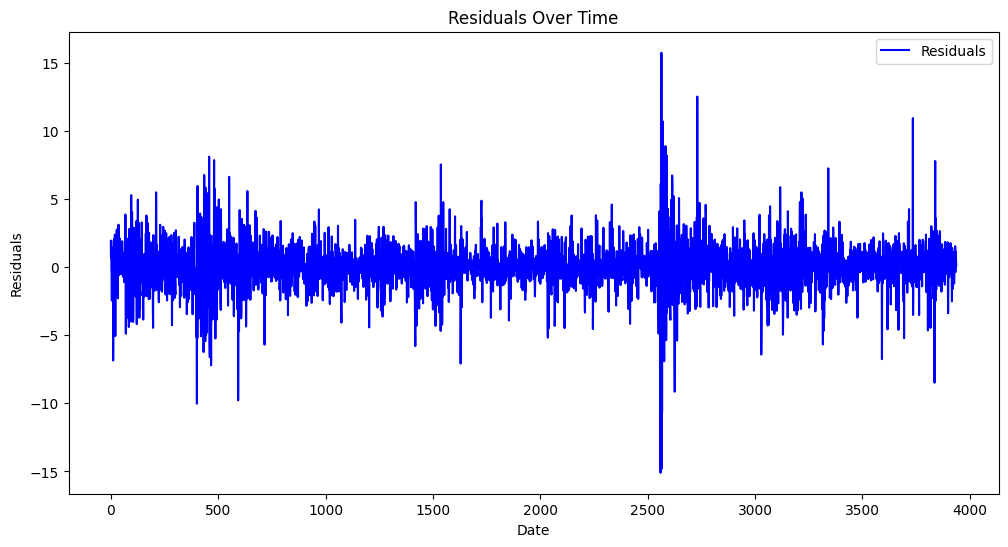

In [78]:
ar_residuals = ar_model.resid

plt.figure(figsize=(12, 6))
plt.plot(ar_residuals, label='Residuals', color='blue')
plt.title("Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.legend()
plt.show()

In [79]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box test
ljung_box_result = acorr_ljungbox(ar_residuals, lags=[np.floor(np.sqrt(len(jpm_return)))], return_df=True)
print(ljung_box_result)

       lb_stat     lb_pvalue
62  151.924514  1.647201e-09


In [80]:
# Rejection of the null hypthesis of absence of serial autocorrelation aming the residuals (assummed iid) 

In [81]:
# Ljung-Box test on the squared residuals
ljung_box_result = acorr_ljungbox(ar_residuals**2, lags=[np.floor(np.sqrt(len(jpm_return)))], return_df=True)
print(ljung_box_result)

        lb_stat  lb_pvalue
62  3682.465171        0.0


In [82]:
# Rejection of the null hypthesis of absence of serial autocorrelation aming the squared residuals (assummed iid) 
# ==> ARCH effect among the residuals

## Moving Average (MA) Model

$$
X_t = \mu + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2} + \dots + \theta_q \epsilon_{t-q}
$$

The MA (Moving Average) model describes the current value (the value of the time series) as being determined by the weighted sum of random error terms.

Select the lag using Autocorrelation Function(ACF) plot

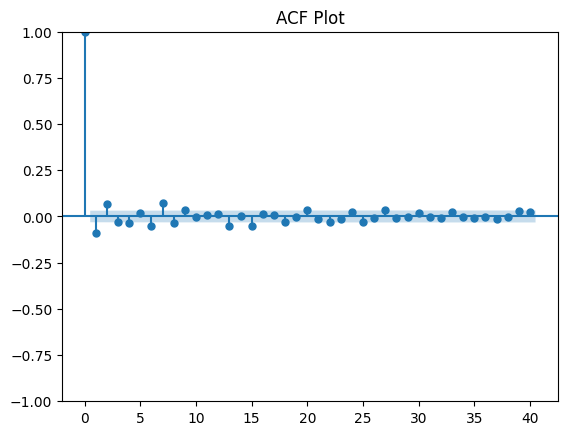

In [83]:
plot_acf(jpm_return, lags=40)
plt.title("ACF Plot")
plt.show()

In [84]:
ma_model = ARIMA(jpm_return, order=(0, 0, 2)).fit() # (p,d,q)
ma_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 3938
Model:                 ARIMA(0, 0, 2)   Log Likelihood               -7756.788
Date:                Sat, 26 Sep 2026   AIC                          15521.576
Time:                        13:18:38   BIC                          15546.690
Sample:                             0   HQIC                         15530.485
                               - 3938                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0597      0.028      2.137      0.033       0.005       0.115
ma.L1         -0.0795      0.008    -10.357      0.000      -0.094      -0.064
ma.L2          0.0686      0.009      7.525      0.000       0.051       0.086
sigma2         3.0090      0.031     96.174      0.000       2.948       3.070
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):             12024.43
Prob(Q):                              0.88   Prob(JB):                         0.00
Heteroskedasticity (H):               0.84   Skew:                            -0.10
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.56
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

Prediction for next period

In [85]:
forecast = ma_model.forecast(steps=1)
forecast

array([0.08719406])

In [86]:
ma_residuals = ma_model.resid

ljung_box_result = acorr_ljungbox(ma_residuals, lags=[np.floor(np.sqrt(len(jpm_return)))], return_df=True)
print(ljung_box_result)

       lb_stat     lb_pvalue
62  139.020381  7.719742e-08


In [87]:
ljung_box_result = acorr_ljungbox(ma_residuals, lags=[5,10,15,20,25], return_df=True)
print(ljung_box_result)

      lb_stat     lb_pvalue
5    9.462008  9.199561e-02
10  37.872884  3.993468e-05
15  57.718474  6.195433e-07
20  68.926417  2.724273e-07
25  80.026634  1.130146e-07


In [88]:
# Rejection of the null hypthesis of absence of serial autocorrelation among the residuals (assummed iid) 

## Autoregressive Moving Average (ARMA) Model

$$
X_t = \mu + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \dots + \phi_p X_{t-p} + \epsilon_t + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2} + \dots + \theta_q \epsilon_{t-q}
$$

In [89]:
arma_model = ARIMA(jpm_return, order=(2, 0, 2)).fit()
arma_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                 3938
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -7740.999
Date:                Sat, 26 Sep 2026   AIC                          15493.998
Time:                        13:18:43   BIC                          15531.668
Sample:                             0   HQIC                         15507.362
                               - 3938                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0597      0.027      2.250      0.024       0.008       0.112
ar.L1         -1.5985      0.028    -56.975      0.000      -1.653      -1.543
ar.L2         -0.8052      0.026    -30.544      0.000      -0.857      -0.754
ma.L1          1.5153      0.032     47.327      0.000       1.453       1.578
ma.L2          0.7313      0.030     24.277      0.000       0.672       0.790
sigma2         2.9848      0.032     93.852      0.000       2.923       3.047
===================================================================================
Ljung-Box (L1) (Q):                   0.20   Jarque-Bera (JB):             10584.59
Prob(Q):                              0.65   Prob(JB):                         0.00
Heteroskedasticity (H):               0.84   Skew:                            -0.12
Prob(H) (two-sided):                  0.00   Kurtosis:                        11.03
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [90]:
arma_model.forecast(steps = 1)

array([-0.00349433])

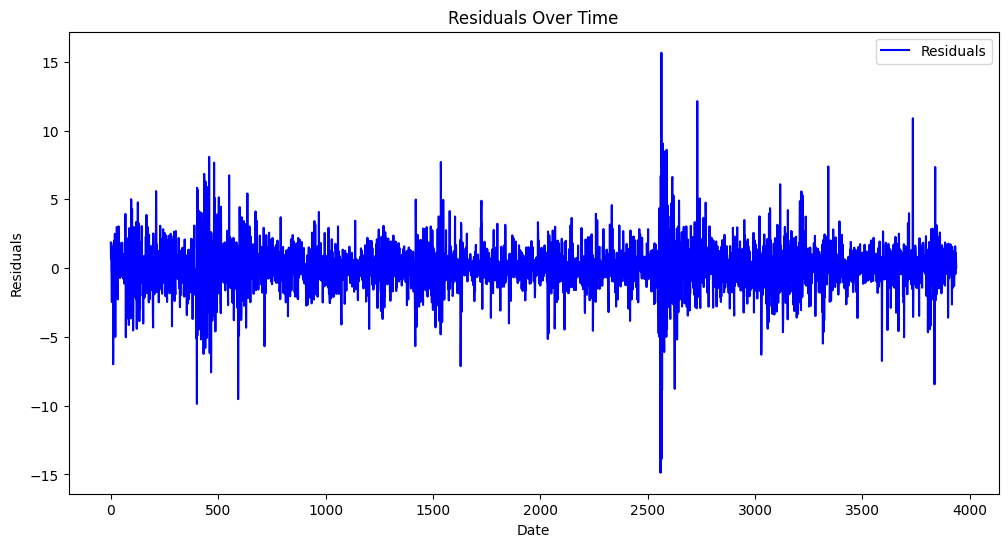

In [91]:
arma_residuals = arma_model.resid

plt.figure(figsize=(12, 6))
plt.plot(arma_residuals, label='Residuals', color='blue')
plt.title("Residuals Over Time")
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.legend()
plt.show()

In [92]:
ljung_box_result = acorr_ljungbox(arma_residuals, lags=[np.floor(np.sqrt(len(jpm_return)))], return_df=True)
print(ljung_box_result)

       lb_stat  lb_pvalue
62  104.672541   0.000574


In [93]:
# Rejection of the null hypthesis of absence of serial autocorrelation among the residuals (assummed iid), however the degree of confidence
# start geting slightly lower

In [94]:
ljung_box_result = acorr_ljungbox(arma_residuals**2, lags=[np.floor(np.sqrt(len(jpm_return)))], return_df=True)
print(ljung_box_result)

      lb_stat  lb_pvalue
62  3326.7336        0.0


In [95]:
# Same conclusion as before, there still is ARCH effecrt among the rediduals 

In [96]:
from statsmodels.stats.diagnostic import het_arch #Engle’s ARCH test

arch_test_result = het_arch(arma_residuals)
print(f"ARCH LM Test Statistic: {arch_test_result[0]}")
print(f"p-value: {arch_test_result[1]}")

ARCH LM Test Statistic: 782.2506185771931
p-value: 1.3487818175565266e-161


In [97]:
# Rejection of the null hypthesis of absence of arch effect among the residuals (assummed iid ie. homoskedastic)
# The arch effect is the linear relationship between the squarred residuals here

## Generalized Autoregressive Conditional Heteroskedasticity (GARCH) Model

$$
X_t = \mu + \epsilon_t
$$

$$
\epsilon_t = \sigma_t z_t
$$

$$
\sigma_t^2 = \alpha_0 + \sum_{i=1}^{q} \alpha_i \epsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j \sigma_{t-j}^2
$$

In [98]:
from arch import arch_model

We can choose mean = 'Zero', 'Constant', 'AR'

dist = 'Normal', 't', 'skewt', etc.

In [99]:
garch_model = arch_model(jpm_return, mean='Zero', vol='GARCH', p=1, q=1, dist='Normal').fit(disp="off")
garch_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                       Zero Mean - GARCH Model Results                        
==============================================================================
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7237.20
Distribution:                  Normal   AIC:                           14480.4
Method:            Maximum Likelihood   BIC:                           14499.2
                                        No. Observations:                 3938
Date:                Sat, Sep 26 2026   Df Residuals:                     3938
Time:                        13:18:43   Df Model:                            0
                             Volatility Model                             
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.0999  4.179e-02      2.392  1.678e-02 [1.804e-02,  0.182]
alpha[1]       0.0896  2.424e-02      3.698  2.177e-04 [4.213e-02,  0.137]
beta[1]        0.8735  3.714e-02     23.519 2.637e-122   [  0.801,  0.946]
==========================================================================

Covariance estimator: robust
"""

In [100]:
# Extract residuals
eps = garch_model.resid               # epsilon_t
sigma = garch_model.conditional_volatility    # sigma_t
z = garch_model.std_resid                     # standardized residuals: z_t = eps_t / sigma_t

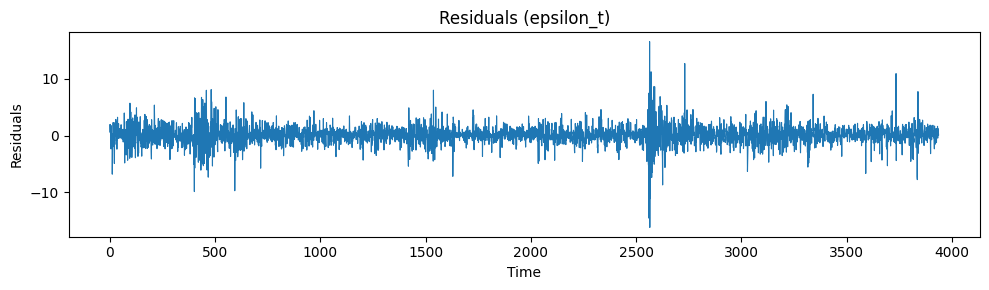

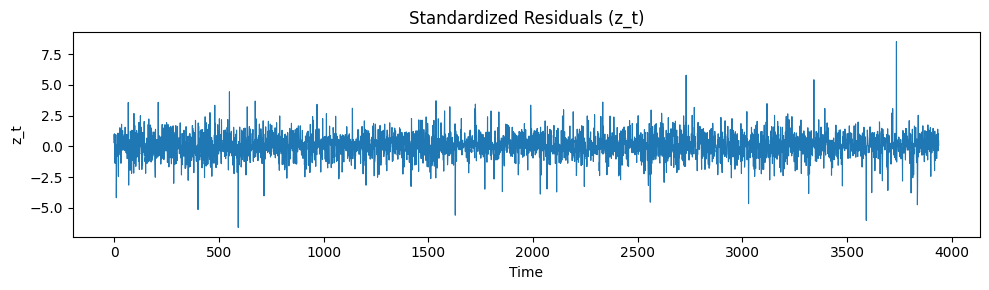

In [101]:
# Residuals over time
plt.figure(figsize=(10, 3))
plt.plot(eps, lw=0.8)
plt.title("Residuals (epsilon_t)")
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

# Standardized residuals over time
plt.figure(figsize=(10, 3))
plt.plot(z, lw=0.8)
plt.title("Standardized Residuals (z_t)")
plt.xlabel("Time")
plt.ylabel("z_t")
plt.tight_layout()
plt.show()

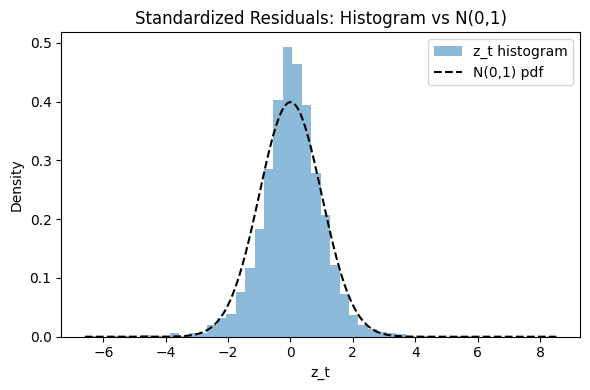

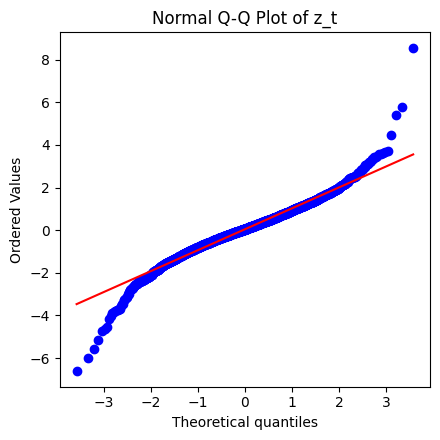

In [102]:
from scipy.stats import norm, probplot, skew, kurtosis

# Histogram of z with standard normal pdf
plt.figure(figsize=(6, 4))
count, bins, _ = plt.hist(z, bins=50, density=True, alpha=0.5, edgecolor="none", label="z_t histogram")
x = np.linspace(z.min(), z.max(), 400)
plt.plot(x, norm.pdf(x), "k--", label="N(0,1) pdf")
plt.title("Standardized Residuals: Histogram vs N(0,1)")
plt.xlabel("z_t")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# Normal Q-Q plot for z
plt.figure(figsize=(4.5, 4.5))
probplot(z, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot of z_t")
plt.tight_layout()
plt.show()


In [103]:
# Much fatter tails than the gaussian law

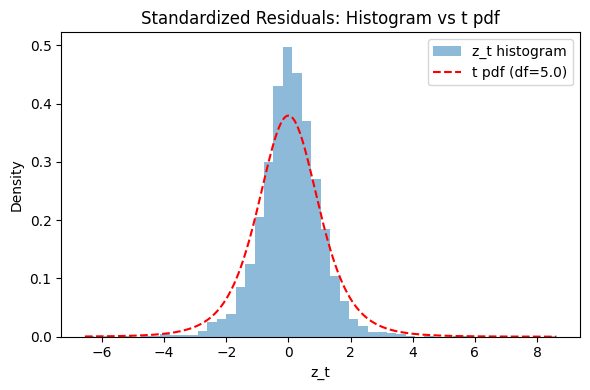

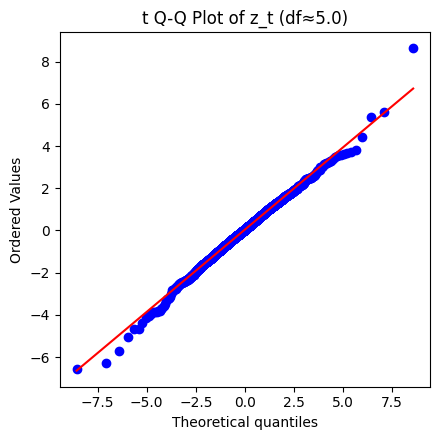

In [104]:
from scipy.stats import t as student_t, probplot

am_t = arch_model(jpm_return, mean='Zero', vol='GARCH', p=1, q=1, dist='t')
res_t = am_t.fit(disp="off")

#Extract standardized residuals and estimated df
z_t = res_t.std_resid     # standardized residuals: epsilon_t / sigma_t
df_t = float(res_t.params.get("nu"))  # estimated degrees of freedom

#Histogram with Student-t pdf 
plt.figure(figsize=(6, 4))
plt.hist(z_t, bins=50, density=True, alpha=0.5, edgecolor="none", label="z_t histogram")
x = np.linspace(z_t.min(), z_t.max(), 400)
plt.plot(x, student_t.pdf(x, df=df_t), "r--", label=f"t pdf (df={df_t:.1f})")
plt.title("Standardized Residuals: Histogram vs t pdf")
plt.xlabel("z_t")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

# Student-t Q-Q plot for z_t
plt.figure(figsize=(4.5, 4.5))
probplot(z_t, dist=student_t, sparams=(df_t,), plot=plt)
plt.title(f"t Q-Q Plot of z_t (df≈{df_t:.1f})")
plt.tight_layout()
plt.show()

Prediction for next period

In [105]:
res_t.forecast(horizon=1).variance.values[0,0] #one-step-ahead forecast of the conditional variance

np.float64(1.2029414221936796)

In [106]:
np.sqrt(1.202947932289424)

np.float64(1.0967898305005495)

<div class="alert alert-success">
    <b>EXERCISE:</b>
    <ul>
        <li>Write a loop to find the best GARCH model order (<code>p</code>, <code>q</code>) where <code>p</code> ranges from 1 to 5 and <code>q</code> ranges from 1 to 5, using the Bayesian Information Criterion (BIC) for selection.</li>
        <li>Using a rolling window of 252 observations, predict the volatility for the next period for each window.</li>
        <li>Plot the squared predicted volatility against the squared returns for comparison.</li>
    </ul>
</div>

In [107]:
best_bic = np.inf  
best_order = None  

for p in range(1, 6):  
    for q in range(1, 6):  
        model = arch_model(jpm_return, mean='Zero', vol='GARCH', p=p, q=q, dist='t').fit(disp="off")
        if model.bic < best_bic:
            best_bic = model.bic
            best_order = (p, q)

In [108]:
best_order # should have done that in the train or doing a walk forward cv

(1, 1)

In [109]:
rolling_window = 252  
predicted_vol = []  
     
for start in range(len(jpm_return) - rolling_window):
    train_data = jpm_return[start:start + rolling_window]
    model = arch_model(train_data, vol='Garch', p=best_order[0], q=best_order[1]).fit(disp="off") # we can update best params doing cross validation
    forecast = model.forecast(horizon=1)
    predicted_vol.append(np.sqrt(forecast.variance.values[0,0]))

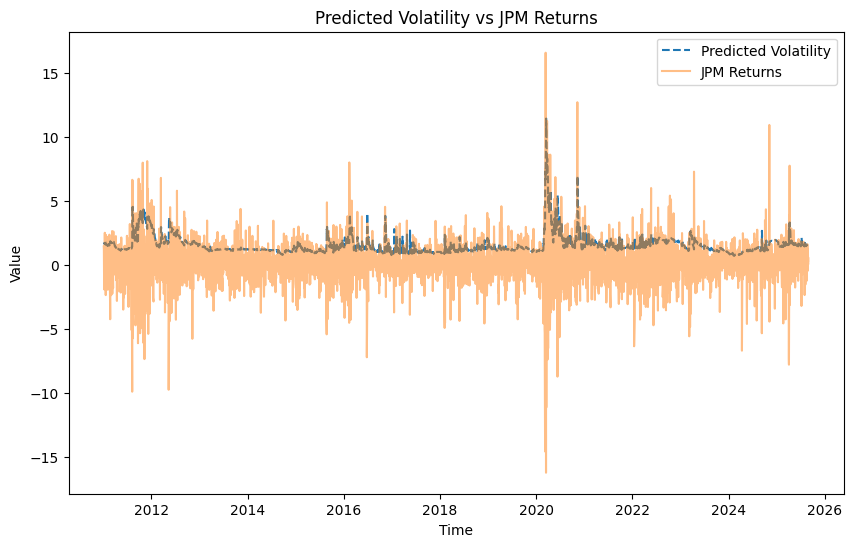

In [110]:
JPM_returns = log_returns['JPM'][rolling_window:]

predicted_vol_series = pd.Series(predicted_vol, index=JPM_returns.index)

comparison_df = pd.DataFrame({
    'Predicted_Vol': predicted_vol_series,
    'Returns': JPM_returns
})

plt.figure(figsize=(10, 6))
plt.plot(comparison_df.index, comparison_df['Predicted_Vol'].apply(lambda x:x), label='Predicted Volatility', linestyle='--')
plt.plot(comparison_df.index, comparison_df['Returns'].apply(lambda x:x), label='JPM Returns', alpha=0.5)
plt.title('Predicted Volatility vs JPM Returns')
plt.xlabel('Time')
plt.ylabel('Value')
plt.legend()
plt.show()

# Linear regression with python

## Data import

We use the Boston real estate price data.

The first 401 observations are used for the estimation of a linear regression and the following observations for the calculation of the forecasts and the measurement of the precision of these forecasts by various criteria.


We will estimate two regressions:
    
     * regression of 'MEDV' (denoted y) on 'RM' denoted (x)
     * regression of 'MEDV' on all the other variables noted X

In [111]:
#MEDV : median Value of owner-occupied home
#RM : average number of rooms par dweling

In [175]:
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']

data = pd.read_csv('housing.csv', header=None, delimiter=r"\s+", names=column_names)
# Separate the data into two sub-samples
# sample 1: up to index 400
# sample 2: from index 401
y1 = data.loc[:400,'MEDV'] #data.iloc[:401,-1]
y2 = data.loc[401:,'MEDV'] #data.iloc[401:,-1]
x1 = data.loc[:400,'RM']  
x2 = data.loc[401:,'RM'] 
X1 = data.loc[:400,data.columns!='MEDV'] 
X2 = data.loc[401:,data.columns!='MEDV'] 

In [113]:
data

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


## Simple linear regression with scikit-learn

Estimating a simple linear regression with **scikit-learn** involves 5 steps:
    
     1. import necessary packages and object classes
    
     2. Importing data and performing appropriate transformations
    
     3. Creation and Estimation of a Regression Model
    
     4. Checking the estimation results
    
     5. forecast with the estimated model
    
    
   
    https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html

### Importing packages

In [114]:
from sklearn.linear_model import LinearRegression

sklearn.linear_model.LinearRegression allows to estimate linear or polynomial regressions and to calculate forecasts with the estimated models.

### Collection of data

We transform the series **y** and **x** into numpy.array

In [178]:
x=np.array(x1)
y=np.array(y1)

x.shape, y.shape

((401,), (401,))

In [179]:
x

array([6.575, 6.421, 7.185, 6.998, 7.147, 6.43 , 6.012, 6.172, 5.631,
       6.004, 6.377, 6.009, 5.889, 5.949, 6.096, 5.834, 5.935, 5.99 ,
       5.456, 5.727, 5.57 , 5.965, 6.142, 5.813, 5.924, 5.599, 5.813,
       6.047, 6.495, 6.674, 5.713, 6.072, 5.95 , 5.701, 6.096, 5.933,
       5.841, 5.85 , 5.966, 6.595, 7.024, 6.77 , 6.169, 6.211, 6.069,
       5.682, 5.786, 6.03 , 5.399, 5.602, 5.963, 6.115, 6.511, 5.998,
       5.888, 7.249, 6.383, 6.816, 6.145, 5.927, 5.741, 5.966, 6.456,
       6.762, 7.104, 6.29 , 5.787, 5.878, 5.594, 5.885, 6.417, 5.961,
       6.065, 6.245, 6.273, 6.286, 6.279, 6.14 , 6.232, 5.874, 6.727,
       6.619, 6.302, 6.167, 6.389, 6.63 , 6.015, 6.121, 7.007, 7.079,
       6.417, 6.405, 6.442, 6.211, 6.249, 6.625, 6.163, 8.069, 7.82 ,
       7.416, 6.727, 6.781, 6.405, 6.137, 6.167, 5.851, 5.836, 6.127,
       6.474, 6.229, 6.195, 6.715, 5.913, 6.092, 6.254, 5.928, 6.176,
       6.021, 5.872, 5.731, 5.87 , 6.004, 5.961, 5.856, 5.879, 5.986,
       5.613, 5.693,

We must transform x into an array of dimension 2: one column and many rows

In [180]:
x=x[:,np.newaxis]
x

array([[6.575],
       [6.421],
       [7.185],
       [6.998],
       [7.147],
       [6.43 ],
       [6.012],
       [6.172],
       [5.631],
       [6.004],
       [6.377],
       [6.009],
       [5.889],
       [5.949],
       [6.096],
       [5.834],
       [5.935],
       [5.99 ],
       [5.456],
       [5.727],
       [5.57 ],
       [5.965],
       [6.142],
       [5.813],
       [5.924],
       [5.599],
       [5.813],
       [6.047],
       [6.495],
       [6.674],
       [5.713],
       [6.072],
       [5.95 ],
       [5.701],
       [6.096],
       [5.933],
       [5.841],
       [5.85 ],
       [5.966],
       [6.595],
       [7.024],
       [6.77 ],
       [6.169],
       [6.211],
       [6.069],
       [5.682],
       [5.786],
       [6.03 ],
       [5.399],
       [5.602],
       [5.963],
       [6.115],
       [6.511],
       [5.998],
       [5.888],
       [7.249],
       [6.383],
       [6.816],
       [6.145],
       [5.927],
       [5.741],
       [5.966],
       [

In [117]:
x.shape

(401, 1)

### Creating a model and estimating with existing data

In [118]:
model = LinearRegression()

In [119]:
model

LinearRegression()

In [120]:
model.fit(x,y)

LinearRegression()

**NB** : sklearn takes the regressor as its first argument and the target as its second

Equivalent writing

In [121]:
model = LinearRegression().fit(x,y)

### Displaying the results of a regression

#### Estimated coefficients

In [122]:
print(model.intercept_, model.coef_) #note the underscore

-35.458131789431576 [9.43054496]


#### $R^{2}$

In [123]:
r_sq =model.score(x,y)
print(f"determination coefficient: {r_sq}")

determination coefficient: 0.5642745121062778


### Forecast: calculation of adjusted variables

Predictions can be calculated for observed values of x (calculation of adjusted variables) or for new values of x.

We use the .predict() function

In [124]:
x_pred =np.array(x2)
x_pred =x_pred[:,np.newaxis]

In [125]:
y_pred = model.predict(x_pred)

In [126]:
print(f"predicted variable:\n{y_pred}")

predicted variable:
[24.35981486 24.9350781  14.98585318 16.70221236 18.13565519  3.56546323
 17.42836432 17.51323922 29.15996224 18.83351552 27.32100598  8.18643026
 13.15632745  7.15850086 25.21799445 28.4998241  14.56147865 20.71962451
 28.89590698 25.00109192 21.18172121 17.80558612 22.09648407 17.02285089
 20.14436127 19.58795911 23.03010802 22.94523312 24.70874502 24.40696759
 28.98078189 25.13311955 25.23685554 23.08669129 27.05695072 25.47261917
 22.55858077 20.51215252 17.60754467 19.40877876 24.95393919 23.19042729
 25.69895224 19.74827838 25.45375808 24.34095377 23.49220472 22.86978876
 25.05767519 28.18861611 27.30214489 23.92600979 34.26188706 27.99057467
 26.07617404 20.89880486 20.52158306 23.96373197 21.88901208 27.73594995
 24.67102284 24.11462069 25.9630075  23.09612184 18.85237661 20.67247178
 21.15342958 20.42727761 18.41857154 22.70003895 23.28473274 25.24628609
 30.367072   15.72143568 22.65288622 25.6895217  14.56147865 22.86978876
 23.28473274 23.40732982 28.198

In [127]:
# alternative method: by calculating y_pred from the linear regression formula

y_pred2 = model.intercept_ + model.coef_*x_pred
print(f"predicted answer from calculation formula:\n{y_pred2}")

predicted answer from calculation formula:
[[24.35981486]
 [24.9350781 ]
 [14.98585318]
 [16.70221236]
 [18.13565519]
 [ 3.56546323]
 [17.42836432]
 [17.51323922]
 [29.15996224]
 [18.83351552]
 [27.32100598]
 [ 8.18643026]
 [13.15632745]
 [ 7.15850086]
 [25.21799445]
 [28.4998241 ]
 [14.56147865]
 [20.71962451]
 [28.89590698]
 [25.00109192]
 [21.18172121]
 [17.80558612]
 [22.09648407]
 [17.02285089]
 [20.14436127]
 [19.58795911]
 [23.03010802]
 [22.94523312]
 [24.70874502]
 [24.40696759]
 [28.98078189]
 [25.13311955]
 [25.23685554]
 [23.08669129]
 [27.05695072]
 [25.47261917]
 [22.55858077]
 [20.51215252]
 [17.60754467]
 [19.40877876]
 [24.95393919]
 [23.19042729]
 [25.69895224]
 [19.74827838]
 [25.45375808]
 [24.34095377]
 [23.49220472]
 [22.86978876]
 [25.05767519]
 [28.18861611]
 [27.30214489]
 [23.92600979]
 [34.26188706]
 [27.99057467]
 [26.07617404]
 [20.89880486]
 [20.52158306]
 [23.96373197]
 [21.88901208]
 [27.73594995]
 [24.67102284]
 [24.11462069]
 [25.9630075 ]
 [23.0961218

### Calculation of forecast accuracy indicators

In [128]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

In [129]:
# OOS
print("Mean squared error: %.2f" %mean_squared_error(y2,y_pred))
print("Mean absolute error: %.2f" %mean_absolute_error(y2,y_pred))
print("Mean absolute percentage error: %.2f" %mean_absolute_percentage_error(y2,y_pred))

Mean squared error: 77.66
Mean absolute error: 7.27
Mean absolute percentage error: 0.61


### Graphics with Scikit-learn

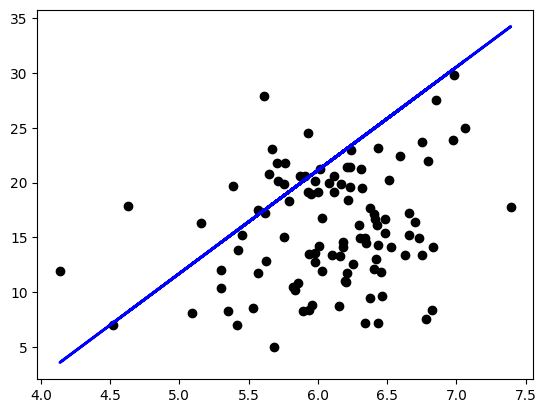

In [130]:
# Use plt.scatter() to plot the actual data and plt.plot() to plot the predicted line
plt.scatter(x2,y2,color="black")
plt.plot(x2,y_pred,color="blue",linewidth=2)
plt.show()

# Multiple linear regression with scikit-learn

In [185]:
X1

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
396,5.87205,0.0,18.10,0,0.693,6.405,96.0,1.6768,24,666.0,20.2,396.90,19.37
397,7.67202,0.0,18.10,0,0.693,5.747,98.9,1.6334,24,666.0,20.2,393.10,19.92
398,38.35180,0.0,18.10,0,0.693,5.453,100.0,1.4896,24,666.0,20.2,396.90,30.59
399,9.91655,0.0,18.10,0,0.693,5.852,77.8,1.5004,24,666.0,20.2,338.16,29.97


In [131]:
X = np.array(X1)
X.shape

(401, 13)

In [132]:
modelall = LinearRegression().fit(X,y)

In [133]:
modelall.intercept_, modelall.coef_

(np.float64(29.005809159425805),
 array([-1.99873534e-01,  4.42763141e-02,  5.55407781e-02,  1.73791950e+00,
        -1.49715808e+01,  4.85503348e+00,  2.90568657e-03, -1.29621067e+00,
         4.83051120e-01, -1.54201512e-02, -8.08704936e-01, -1.49681762e-03,
        -5.23714094e-01]))

In [134]:
r_sq = modelall.score(X,y)
r_sq

0.7352124274349188

In [135]:
x_pred = np.array(X2)
yall_pred = modelall.predict(x_pred)

In [136]:
yall_pred

array([19.58764209, 20.76354217, 12.75957269,  6.50814359,  4.47071337,
        7.06776448, 21.74565968, 15.95336962, 24.20492324, 16.95074641,
       22.71715509,  5.00314396, 12.75920033, -3.93805933, 15.11334105,
       19.96083573,  9.38022995,  6.18728639, 20.93395476, 22.69635683,
       21.1505423 , 20.72383184, 19.452712  , 20.05422324, 15.3052598 ,
       21.47638814, 17.59772885, 19.73056663, 18.96613662, 23.60388292,
       24.55210924, 27.07912512, 23.06445028, 20.9832873 , 19.042609  ,
       20.58685111, 14.69751333,  9.97599707, 14.70273344, 13.44309661,
       19.88244938, 21.39182263, 20.68780896, 14.78663845, 18.22094972,
       21.25012539, 20.52500832, 19.75392824, 20.85956883, 23.87099178,
       22.96188233, 21.45478615, 26.34835019, 22.31633319, 22.5760245 ,
       19.34334812, 19.25826873, 21.09442051, 20.91811464, 23.80887488,
       23.21251458, 22.43899713, 25.43252847, 22.60156251, 20.78470427,
       20.84431998, 19.83648797, 18.3624366 , 19.61912207, 22.57

In [137]:
print("Mean squared error: %.2f" %mean_squared_error(y2,y_pred))
print("Mean absolute error: %.2f" %mean_absolute_error(y2,y_pred))
print("Mean absolute percentage error: %.2f" %mean_absolute_percentage_error(y2,y_pred))

Mean squared error: 77.66
Mean absolute error: 7.27
Mean absolute percentage error: 0.61


In [138]:
print("Mean squared error: %.2f" %mean_squared_error(y2,yall_pred))
print("Mean absolute error: %.2f" %mean_absolute_error(y2,yall_pred))
print("Mean absolute percentage error: %.2f" %mean_absolute_percentage_error(y2,yall_pred))

Mean squared error: 37.14
Mean absolute error: 5.08
Mean absolute percentage error: 0.40


# Linear regressions with statsmodels

### import the packages

In [139]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [140]:
X1=sm.add_constant(X1) # statsmodels does not add a default constant in linear regressions. It needs to be added.
regall=sm.OLS(y1,X1).fit()
regall.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.735
Model:                            OLS   Adj. R-squared:                  0.726
Method:                 Least Squares   F-statistic:                     82.66
Date:                Sat, 26 Sep 2026   Prob (F-statistic):          5.72e-103
Time:                        13:21:04   Log-Likelihood:                -1192.1
No. Observations:                 401   AIC:                             2412.
Df Residuals:                     387   BIC:                             2468.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         29.0058      6.155      4.712      0.000      16.903      41.108
CRIM          -0.1999      0.054     -3.717      0.000      -0.306      -0.094
ZN             0.0443      0.014      3.133      0.002       0.016       0.072
INDUS          0.0555      0.066      0.846      0.398      -0.073       0.185
CHAS           1.7379      0.892      1.948      0.052      -0.016       3.492
NOX          -14.9716      4.564     -3.281      0.001     -23.944      -5.999
RM             4.8550      0.485     10.009      0.000       3.901       5.809
AGE            0.0029      0.014      0.203      0.840      -0.025       0.031
DIS           -1.2962      0.212     -6.114      0.000      -1.713      -0.879
RAD            0.4831      0.087      5.523      0.000       0.311       0.655
TAX           -0.0154      0.004     -3.463      0.001      -0.024      -0.007
PTRATIO       -0.8087      0.140     -5.765      0.000      -1.084      -0.533
B             -0.0015      0.007     -0.229      0.819      -0.014       0.011
LSTAT         -0.5237      0.059     -8.809      0.000      -0.641      -0.407
==============================================================================
Omnibus:                      117.115   Durbin-Watson:                   1.124
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              533.859
Skew:                           1.189   Prob(JB):                    1.19e-116
Kurtosis:                       8.128   Cond. No.                     1.53e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.53e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [141]:
# Display of estimated coefficients
regall.params

const      29.005809
CRIM       -0.199874
ZN          0.044276
INDUS       0.055541
CHAS        1.737919
NOX       -14.971581
RM          4.855033
AGE         0.002906
DIS        -1.296211
RAD         0.483051
TAX        -0.015420
PTRATIO    -0.808705
B          -0.001497
LSTAT      -0.523714
dtype: float64

In [142]:
# Display of the t-stat of the estimated coefficients
regall.tvalues

const       4.712192
CRIM       -3.717344
ZN          3.133458
INDUS       0.846410
CHAS        1.947831
NOX        -3.280618
RM         10.009301
AGE         0.202520
DIS        -6.114054
RAD         5.523423
TAX        -3.462856
PTRATIO    -5.765260
B          -0.228740
LSTAT      -8.808861
dtype: float64

In [143]:
# Display pvalue of the F-stat
regall.f_pvalue

np.float64(5.723074494441148e-103)

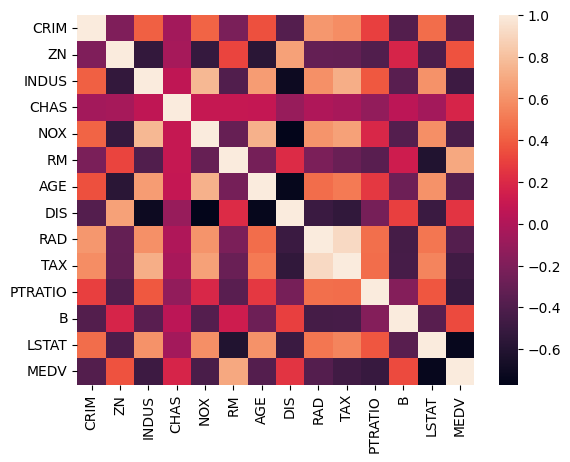

In [144]:
#correlation matrix
sns.heatmap(data.corr())
plt.show()

In [145]:
# If we want to check that the correlation is significantly different from 0
from scipy import stats
stats.pearsonr(data['AGE'].to_numpy(),data['DIS'].to_numpy())

PearsonRResult(statistic=np.float64(-0.747880540868632), pvalue=np.float64(9.857534072929312e-92))

In [146]:
# Display R² and adjusted R²
regall.rsquared, regall.rsquared_adj

(np.float64(0.7352124274349188), np.float64(0.7263177544546964))

In [147]:
# Display of residuals
regall.resid

0     -5.028220
1     -3.195017
2      3.565183
3      4.113161
4      7.427759
         ...   
396   -9.413211
397   -9.641160
398   -0.177578
399   -6.832311
400   -6.701627
Length: 401, dtype: float64

In [148]:
regall.aic

np.float64(2412.129104803886)

In [149]:
dir(regall) # list of all objects that can be retrieved from the results

['HC0_se',
 'HC1_se',
 'HC2_se',
 'HC3_se',
 '_HCCM',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abat_diagonal',
 '_cache',
 '_data_attr',
 '_data_in_cache',
 '_get_robustcov_results',
 '_get_wald_nonlinear',
 '_is_nested',
 '_transform_predict_exog',
 '_use_t',
 '_wexog_singular_values',
 'aic',
 'bic',
 'bse',
 'centered_tss',
 'compare_f_test',
 'compare_lm_test',
 'compare_lr_test',
 'condition_number',
 'conf_int',
 'conf_int_el',
 'cov_HC0',
 'cov_HC1',
 'cov_HC2',
 'cov_HC3',
 'cov_kwds',
 'cov_params',
 'cov_type',
 'df_model',
 'df_resid',
 'diagn',
 'eigenvals',
 'el_test',
 'ess',
 'f_pval

### Estimating models with a formula
we use the library **statsmodels.formula.api**

In [150]:
reg1 = smf.ols('MEDV~CRIM+PTRATIO',data=data).fit() # lowercase ols

In [151]:
reg1.params

Intercept    57.378345
CRIM         -0.281425
PTRATIO      -1.832979
dtype: float64

In [152]:
## display results
reg1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.321
Model:                            OLS   Adj. R-squared:                  0.319
Method:                 Least Squares   F-statistic:                     119.1
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           4.65e-43
Time:                        13:21:04   Log-Likelihood:                -1742.2
No. Observations:                 506   AIC:                             3490.
Df Residuals:                     503   BIC:                             3503.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     57.3783      2.989     19.198      0.000      51.506      63.250
CRIM          -0.2814      0.041     -6.857      0.000      -0.362      -0.201
PTRATIO       -1.8330      0.163    -11.242      0.000      -2.153      -1.513
==============================================================================
Omnibus:                      130.994   Durbin-Watson:                   0.819
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              334.702
Skew:                           1.287   Prob(JB):                     2.09e-73
Kurtosis:                       6.041   Cond. No.                         169.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

We present the estimation of a regression by OLS. However, you can also do:
    
* GLS: generalized least squares
    
* WLS: weighted least squares

## Programming a linear regression

### Linear regression model
We assume that we have $P$ pairs of variables $(y_{p},x_{p})$ where $y_{p}$ is the explained variable and $x_{p}=(x_{1p} ,...,x_{Np})^{T}$ is the column vector of the $N$ explanatory variables (for the individual $p$).
These variables are linked by the linear relationship:
$$
y_{p}= w_{0} + \sum_{i}^{N} w_{i} x_{ip} + e_{p} = w_{0} + x_{p}^{T}w + e_{ p}
$$
where $w=(w_{1},w_{2},...w_{N})^{T}$ is the (N,1) vector of coefficients.

We note $w^{*} = (w_{0},w_{1},...,w_{N})^{T}$ the vector of dimensions (N+1,1) containing the constant $w_ {0}$ and $w$.


Build a Python function, called **model(x,w)**, having as arguments (inputs) $x$ and $w^{*}$ and returning (output) the adjusted values $N$ : $w_{0 } + x_{p}'w$

## Programming a Linear Regression

### 1. Notation

Suppose we observe:

- $P$ observations (or individuals), indexed by $p=1,\ldots,P$;
- $N$ explanatory variables (or features), indexed by $i=1,\ldots,N$.

For observation $p$, we observe:

$$
y_p \in \mathbb{R},
$$

the dependent variable, and

$$
\mathbf{x}_p
=
\begin{pmatrix}
x_{1p}\\
x_{2p}\\
\vdots\\
x_{Np}
\end{pmatrix}
\in\mathbb{R}^{N},
$$

the vector containing the $N$ explanatory variables.

Here,

$$
x_{ip}
=
\text{value of explanatory variable $i$ for observation $p$}.
$$

The linear regression model for observation $p$ is

$$
\boxed{
y_p
=
w_0
+
\mathbf{x}_p^\top\mathbf{w}
+
e_p
}
$$

where

$$
\mathbf{w}
=
\begin{pmatrix}
w_1\\
\vdots\\
w_N
\end{pmatrix}
\in\mathbb{R}^N
$$

contains the slope coefficients and $w_0$ is the intercept.

Equivalently,

$$
y_p
=
w_0
+
\sum_{i=1}^{N}w_i x_{ip}
+
e_p.
$$

We collect all parameters in

$$
\boxed{
\mathbf{w}^*
=
\begin{pmatrix}
w_0\\
w_1\\
\vdots\\
w_N
\end{pmatrix}
\in\mathbb{R}^{N+1}.
}
$$


### 2. The explanatory-variable matrix

In this notebook, we use the convention

$$
\boxed{
X\in\mathbb{R}^{N\times P}.
}
$$

That is:

- each **column** corresponds to one observation;
- each **row** corresponds to one explanatory variable.

Therefore,

$$
X
=
\begin{pmatrix}
x_{11} & x_{12} & \cdots & x_{1P}\\
x_{21} & x_{22} & \cdots & x_{2P}\\
\vdots & \vdots & \ddots & \vdots\\
x_{N1} & x_{N2} & \cdots & x_{NP}
\end{pmatrix}.
$$

Hence,

$$
\boxed{
X_{:,p}
=
\mathbf{x}_p
}
$$

is the vector of the $N$ explanatory variables for observation $p$.

For example,

$$
X_{:,1}
=
\begin{pmatrix}
x_{11}\\
x_{21}\\
\vdots\\
x_{N1}
\end{pmatrix}
=
\mathbf{x}_1.
$$


### 3. Prediction for one observation

For one observation $p$, the predicted value is

$$
\boxed{
\widehat y_p
=
w_0+\mathbf{x}_p^\top\mathbf{w}.
}
$$

Since `w[0]` contains the intercept and `w[1:]` contains the $N$ slope
coefficients, this can be implemented directly in Python.

In [212]:
# # Note: we use the np.dot() matrix product of numpy

def model(x,w):
    y = w[0] + np.dot(x.T,w[1:])
    return y
#Note: we use the np.dot() matrix product of numpy

# def model(x_p, w):
#     """
#     Predict y for one observation.

#     Parameters
#     ----------
#     x_p : array of shape (N,)
#         Explanatory variables for one observation.
#     w : array of shape (N + 1,)
#         Regression parameters:
#         w[0]  = intercept
#         w[1:] = slope coefficients

#     Returns
#     -------
#     y_hat : float
#         Predicted value.
#     """
#     return w[0] + x_p @ w[1:]

### Objective function

We note $y=(y_{1}, y_{2},...,y_{P})$ the sequence of $1 \times P$ explained variables and $x = (x_{1},..., x_{P})$ the (N,p) matrix of explanatory variables.

We are looking for the parameters $w^{*}$ which minimize the least squares cost function:
     $$
     c(w^{*},x,y) = \frac{1}{P} \sum_{i=1}^{P} (y_{i} - w_{0}-x^{T}_{ i}w)^{2}
     $$
    
Build a python function **least_squares(w)** having as arguments $w^{*}, x,y$ and returning the cost function $c(w^{*},x,y)$


x =
\begin{bmatrix}
x_{11} & x_{12} & \dots & x_{1P} \\
x_{21} & x_{22} & \dots & x_{2P} \\
\vdots & \vdots & \ddots & \vdots \\
x_{N1} & x_{N2} & \dots & x_{NP} \\
\end{bmatrix}

In [154]:
def least_squares(w, x, y):
    cost = 0
    for p in range (len(y)):
        cost += (y[p] - model(x[:,p],w))**2
        # we take the p'th column of x so we have a columns vector as in the function model 
    return cost/len(y)

In [155]:
len(y)

401

In [207]:
x = np.array(x1)
# x = np.expand_dims(x,axis = 0) # same for x[np.newaxis,:]
x = x[np.newaxis,:]
y = np.array(y1)
w = np.array([1.0,1.0])

In [158]:
least_squares(w, x, y) 

np.float64(362.28293898254356)

To avoid making the loop, we can use the Numpy function np.sum which calculates the sum of the elements of an array.



In [159]:
def least_squares2(w, x, y):
    cost = np.sum((model(x,w)-y)**2)
    return cost/len(y)

In [160]:
least_squares2(w, x, y)

np.float64(362.28293898254367)

# Excercise

###  Stability of $ \beta_i $

We consider the following decomposition of the return of an asset $ i $:

$$
r_{it} = \alpha_i + \beta_i r_{mt} + e_{it}
$$

where $ r_{it} $ is the return on asset $ i $ and $ r_{mt} $ is the return on the stock market index. The term $ \beta_i r_{mt} $ measures the common variations to all assets, the residual $ e_{it} $ represents the specific risk of each asset.

The value of $ \beta_i $ determines the risk of asset $ i $ relative to the market portfolio:

- $ \beta_i = 1 $: asset $ i $ is as risky as the market portfolio.
- $ \beta_i < 1 $: asset $ i $ is less risky than the market portfolio.
- $ \beta_i > 1 $: asset $ i $ is more risky than the market portfolio.


---
1. **Import Excercise.csv**

2. **Select 10 securities at random.** For each of the $ n = 10 $ securities, estimate by the **OLS regression**: $ r_{it} = \alpha_i + \beta_i r_{mt} + e_{it} $ with $ t = 1, \dots, 40 $ first observations. The estimated model is noted

    $$
    r_{it} = \hat{\alpha}_i + \hat{\beta}_i r_{mt} + \hat{e}_{it}, \quad t = 1, \dots, 40
    $$

    We note $ \beta_{i,40} $ as the $ \beta $ of asset $ i $ obtained from the 40 first observations.

3. **Estimate the same regression** for the equally weighted portfolio of $ n = 10 $ securities $ r_{pt} = \frac{1}{n} \sum_{i=1}^{n} r_{it} $

    $$
    r_{pt} = \alpha_p + \beta_p r_{mt} + e_{pt}, \quad t = 1, \dots, 40
    $$

    It can be shown that $ \alpha_p = \frac{1}{n} \sum_{i=1}^{n} \alpha_i $ and $ \beta_p = \frac{1}{n} \sum_{i=1}^{n} \beta_i $.

4. **Re-estimate the previous regressions for each security and the portfolio** by adding the following observations one by one to the first 40 observations. We will obtain for each asset a sequence of $ \beta_{i,40}, \beta_{i,41}, \dots, \beta_{i,T} $ where $ T $ is the end date of the sample. For each sequence of $ \beta_{i,40}, \beta_{i,41}, \dots, \beta_{i,T} $, calculate:

    - the mean,
    - the minimum, the maximum,
    - the standard deviation

In [161]:
import statsmodels.api as sm 

Q1

In [162]:
data = pd.read_csv('Exercise.csv',delimiter=r"\s+",encoding='latin_1')
data

,Dates,ASML_Holding,LVMH,Lindle_PLC,TOTALENERGIES,SANOFI,SAP,L'OREAL,SIEMENS,ALLIANZ,...,ENI,Volkswagen,CRH,Nokia,Inditex,BMW,Adidas,Flutter,VONOVIA,EUROSTOXX50
0,03/01/2022,795.739990,838.309998,346.420013,50.720001,50.680000,140.320007,425.250000,152.899994,208.050003,...,28.059999,178.000000,53.040001,6.32,31.780001,88.910004,254.350006,11750.0,49.279999,4303.939941
1,04/01/2022,793.630005,838.570007,338.959991,51.060001,49.630001,141.110001,429.399994,154.279999,210.449997,...,28.530001,181.839996,54.049999,6.30,32.230000,91.889999,259.750000,11645.0,49.389999,4346.450195
2,05/01/2022,765.909973,848.500000,347.690002,52.209999,50.119999,141.639999,430.600006,154.919998,217.000000,...,28.809999,187.279999,54.119999,6.26,32.849998,94.500000,260.000000,11630.0,49.310001,4368.779785
3,06/01/2022,739.530029,831.099976,344.679993,52.410000,50.250000,137.259995,421.000000,154.919998,216.350006,...,28.879999,187.300003,53.430000,6.09,32.200001,94.699997,257.149994,11330.0,48.549999,4372.450195
4,07/01/2022,758.390015,822.890015,338.019989,52.549999,50.180000,137.070007,411.649994,153.759995,220.750000,...,28.900000,189.720001,52.869999,6.15,32.000000,96.000000,252.500000,11285.0,48.380001,4331.069824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
243,22/12/2022,571.049988,719.359985,326.329987,63.060001,48.180000,104.180000,353.700012,134.779999,205.199997,...,28.700001,137.160004,39.689999,4.60,26.590000,83.800003,122.800003,11675.0,23.950001,3808.530029
244,23/12/2022,546.869995,718.900024,326.179993,62.529999,48.070000,103.220001,353.000000,132.380005,203.000000,...,28.469999,136.440002,39.619999,4.60,26.770000,83.309998,122.000000,11455.0,24.139999,3790.580078
245,27/12/2022,546.049988,710.000000,330.660004,63.470001,48.320000,103.330002,337.950012,127.879997,199.000000,...,28.870001,133.759995,39.810001,4.62,26.879999,82.790001,117.959999,11615.0,23.400000,3810.870117
246,28/12/2022,536.700012,717.099976,328.839996,64.000000,48.049999,102.870003,336.649994,126.720001,198.360001,...,29.150000,121.099998,40.029999,4.60,26.799999,82.970001,122.900002,11375.0,21.500000,3870.979980


In [163]:
data['Dates'] = pd.to_datetime(data['Dates'],format = '%d/%m/%Y')
data.set_index('Dates', inplace = True)
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 248 entries, 2022-01-03 to 2022-12-29
Data columns (total 51 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ASML_Holding      248 non-null    float64
 1   LVMH              248 non-null    float64
 2   Lindle_PLC        248 non-null    float64
 3   TOTALENERGIES     248 non-null    float64
 4   SANOFI            248 non-null    float64
 5   SAP               248 non-null    float64
 6   L'OREAL           248 non-null    float64
 7   SIEMENS           248 non-null    float64
 8   ALLIANZ           248 non-null    float64
 9   SCHNEIDER         248 non-null    float64
 10  Deutsche_Telekom  248 non-null    float64
 11  AIR_LIQUIDE       248 non-null    float64
 12  IBERDROLA         248 non-null    float64
 13  AIRBUS            248 non-null    float64
 14  BNPP              248 non-null    float64
 15  BAYER             248 non-null    float64
 16  AXA               248 non

In [164]:
df_log = np.log(data/data.shift(1)).dropna()*100
df_log

,ASML_Holding,LVMH,Lindle_PLC,TOTALENERGIES,SANOFI,SAP,L'OREAL,SIEMENS,ALLIANZ,SCHNEIDER,...,ENI,Volkswagen,CRH,Nokia,Inditex,BMW,Adidas,Flutter,VONOVIA,EUROSTOXX50
Dates,,,,,,,,,,,,,,,,,,,,,
2022-01-04,-0.265512,0.031011,-2.176987,0.668110,-2.093585,0.561416,0.971164,0.898505,1.146963,1.334188,...,1.661116,2.134361,1.886316,-0.316957,1.406050,3.296753,2.100834,-0.897634,0.222966,0.982860
2022-01-05,-3.555273,1.177202,2.542920,2.227260,0.982460,0.374889,0.279073,0.413971,3.064927,-0.306310,...,0.976631,2.947766,0.129426,-0.636945,1.905399,2.800764,0.096200,-0.128894,-0.162103,0.512428
2022-01-06,-3.504975,-2.071999,-0.869485,0.382338,0.259044,-3.141172,-2.254677,0.000000,-0.299986,-1.131253,...,0.242677,0.010681,-1.283140,-2.753210,-1.998520,0.211413,-1.102208,-2.613389,-1.553275,0.083979
2022-01-07,2.518290,-0.992754,-1.951140,0.266767,-0.139401,-0.138511,-2.245937,-0.751593,2.013335,-1.586869,...,0.069232,1.283768,-1.053633,0.980400,-0.623058,1.363422,-1.824830,-0.397966,-0.350765,-0.950895
2022-01-10,-5.679160,-2.821082,-1.370204,1.022351,0.079683,0.029174,-0.304118,-1.019749,1.014093,-1.588734,...,-0.138501,-0.380229,-0.550019,-1.144739,1.087806,2.560681,-2.547017,2.321103,-2.278765,-0.438263
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-12-22,0.349088,0.510081,0.082769,0.876016,-0.165902,-0.602900,0.737803,0.401453,0.611025,1.840982,...,0.384015,0.673008,-0.151060,0.000000,0.150550,-1.139071,4.548137,2.120833,4.614231,-0.588257
2022-12-23,-4.326565,-0.063961,-0.045974,-0.844024,-0.228572,-0.925753,-0.198107,-1.796720,-1.077912,-1.449813,...,-0.804629,-0.526318,-0.176523,0.000000,0.674665,-0.586448,-0.653600,-1.902349,0.790181,-0.472423
2022-12-27,-0.150058,-1.245733,1.364131,1.492094,0.518727,0.106513,-4.357007,-3.458431,-1.990115,-4.616208,...,1.395216,-1.983786,0.478415,0.433840,0.410062,-0.626127,-3.367547,1.387105,-3.113415,0.533848


Q2

In [165]:
np.random.seed(9)  
columns = np.random.choice(df_log.columns[:-1], size=10, replace=False)  
market_index = df_log.columns[-1]  

reg_results = pd.DataFrame(index=columns, columns=['Alpha', 'Beta'])

for col in columns:
    y = df_log[col].iloc[:40]  
    x = df_log[market_index].iloc[:40]  
    x = sm.add_constant(x)  

    model = sm.OLS(y, x).fit(disp="off")

    reg_results.loc[col, 'Alpha'] = model.params[0]
    reg_results.loc[col, 'Beta'] = model.params[1]

In [166]:
reg_results

,Alpha,Beta
Anheuser,-0.113851,0.205589
Infineon,-0.531435,1.0158
Lindle_PLC,-0.445806,0.226258
BNPP,-0.144013,0.809148
Nokia,-0.438769,0.156644
SIEMENS,-0.27986,1.014387
BAYER,0.36348,0.749239
Hermès,-0.447596,0.718465
Nordea,-0.196151,-0.129866
BASF,0.037882,0.826837


Q3

In [167]:
portfolio_returns = df_log[columns].iloc[:40].mean(axis=1)  
market_returns = df_log[market_index].iloc[:40]
x_portfolio = sm.add_constant(market_returns)
portfolio_model = sm.OLS(portfolio_returns, x_portfolio).fit(disp="off")

alpha_p = portfolio_model.params[0]
beta_p = portfolio_model.params[1]

In [168]:
alpha_p

np.float64(-0.21961184090977506)

In [169]:
beta_p

np.float64(0.5592500797605635)

In [170]:
reg_results['Beta'].mean()

np.float64(0.5592500797605635)

Q4

In [171]:
beta_df = pd.DataFrame(index=df_log.index[40:], columns=columns)
for t in range(41, len(df_log) + 1):
    market_returns = df_log[market_index].iloc[:t]
    for col in columns:
        y = df_log[col].iloc[:t]
        x = sm.add_constant(market_returns)
        model = sm.OLS(y, x).fit(disp="off")
        beta_df.loc[df_log.index[t-1], col] = model.params[1]
beta_df = beta_df.astype(float)
beta_df

,Anheuser,Infineon,Lindle_PLC,BNPP,Nokia,SIEMENS,BAYER,Hermès,Nordea,BASF
Dates,,,,,,,,,,
2022-03-03,0.201752,1.006821,0.213596,0.816636,0.161229,1.008254,0.739876,0.706857,-0.122595,0.833182
2022-03-04,0.392162,1.014827,0.355273,1.243807,0.488608,1.038879,0.601155,0.698173,-0.104160,0.863670
2022-03-07,0.318078,1.050104,0.370753,1.422813,0.486544,1.091338,0.628823,0.733815,-0.160529,0.923787
2022-03-08,0.347223,1.038501,0.402116,1.386078,0.465097,1.104523,0.628976,0.755270,0.100094,0.996650
2022-03-09,-0.012594,1.285173,0.132777,1.515909,0.182962,1.202926,0.800308,0.835596,0.036632,1.191636
...,...,...,...,...,...,...,...,...,...,...
2022-12-22,-0.024589,0.785680,0.237777,0.641615,0.160423,0.787191,0.304460,0.591027,0.068175,0.603612
2022-12-23,-0.024070,0.787479,0.237708,0.642132,0.160250,0.788425,0.305003,0.591176,0.066129,0.604313
2022-12-27,-0.023309,0.781271,0.239223,0.637649,0.160820,0.783745,0.300923,0.585979,0.066352,0.601184


In [172]:
beta_df.describe()

,Anheuser,Infineon,Lindle_PLC,BNPP,Nokia,SIEMENS,BAYER,Hermès,Nordea,BASF
count,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000,207.000000
mean,0.019745,1.042988,0.245675,0.977389,0.231213,1.043385,0.436421,0.749753,0.053346,0.853740
std,0.057015,0.180431,0.044581,0.263654,0.051332,0.174870,0.122891,0.104047,0.033539,0.212241
min,-0.052494,0.772603,0.132777,0.637649,0.155936,0.774560,0.286632,0.581662,-0.160529,0.599706
25%,-0.022745,0.869922,0.213653,0.711246,0.187749,0.871955,0.326995,0.638312,0.037748,0.654423
50%,0.023160,0.995023,0.238936,0.906862,0.241592,1.007089,0.399660,0.734040,0.056020,0.771505
75%,0.044584,1.248167,0.287102,1.258434,0.261596,1.248744,0.525033,0.853411,0.073247,1.087858
max,0.392162,1.346743,0.402116,1.658588,0.488608,1.303552,0.848959,0.917158,0.100094,1.295822


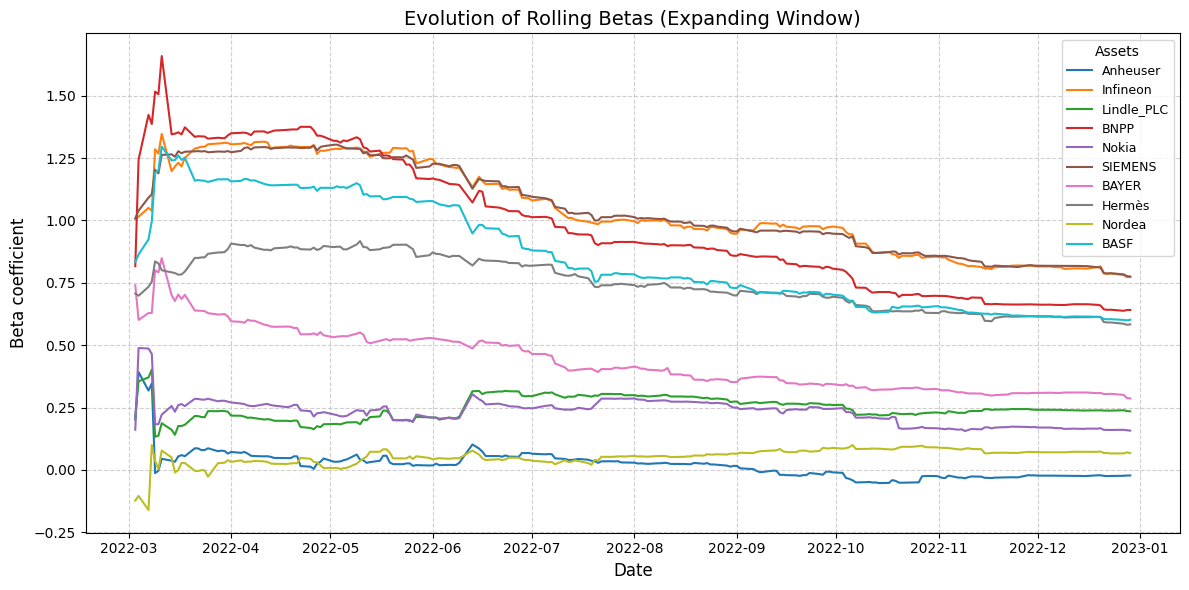

In [173]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 6))

for col in beta_df.columns:
    plt.plot(beta_df.index, beta_df[col], label=col, linewidth=1.5)

plt.title("Evolution of Rolling Betas (Expanding Window)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Beta coefficient", fontsize=12)
plt.legend(title="Assets", loc="best", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()